In [4]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import brian2tools
%matplotlib inline

INFO:root:building '_cython_magic_69a77709a1a8f65573ab2cfd7ad06480' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_69a77709a1a8f65573ab2cfd7ad06480.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_69a77709a1a8f65573ab2cfd7ad06480.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_69a77709a1a8f65573ab2cfd7ad06480.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

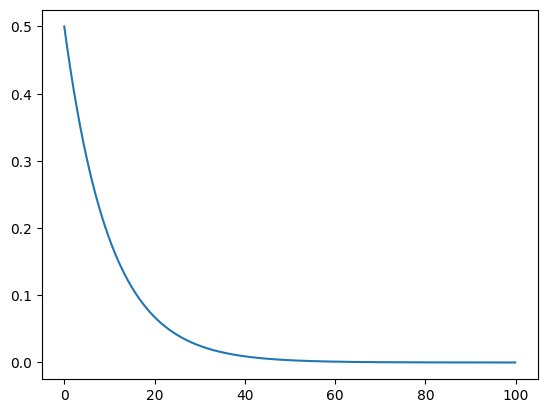

In [ ]:
tau=10*ms
eqs='''
dV/dt=-V/tau : 1
'''
G=NeuronGroup(1,eqs,method='exact')
G.V=0.5
M=StateMonitor(G,'V', record=True)

run(100*ms)
plot(M.t/ms, M.V[0])

In [16]:
import logging

# Set the logging level to WARNING to suppress INFO messages
logging.basicConfig(level=logging.WARNING)

INFO:root:building '_cython_magic_8e79f68bfdd6f9a0a4bd3034def87c9c' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_8e79f68bfdd6f9a0a4bd3034def87c9c.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_8e79f68bfdd6f9a0a4bd3034def87c9c.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_8e79f68bfdd6f9a0a4bd3034def87c9c.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

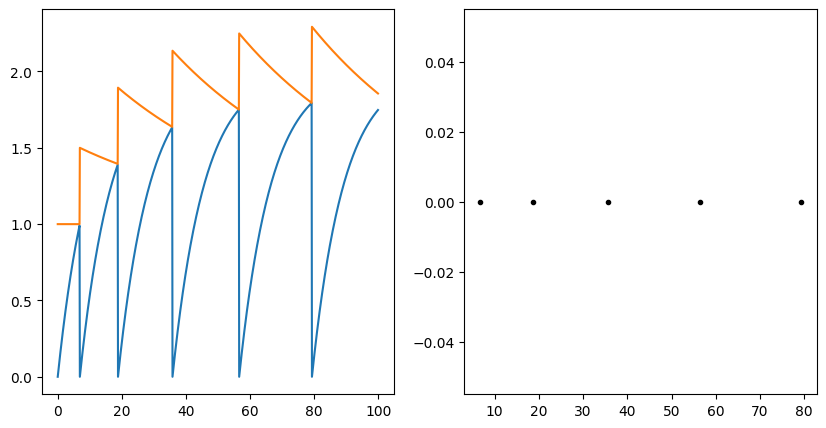

In [17]:
start_scope()

tau=10*ms
tau_t=50*ms
f=100*Hz
eqs='''
dv/dt = (2-v)/tau : 1
dvt/dt = (1-vt)/tau_t : 1
'''
G=NeuronGroup(1,eqs,threshold='v>vt',reset='v=0; vt+=0.5',method='euler')
G.vt=1
M=StateMonitor(G,('v','vt'), record=True)
spM = SpikeMonitor(G)



run(100*ms)
figure(figsize=(10,5))
subplot(121)
plot(M.t/ms, M.v[0])
plot(M.t/ms, M.vt[0])
subplot(122)
plt.plot(spM.t/ms, spM.i, '.k')

In [28]:
print(spM.t)
print(spM.i)

<spikemonitor_2.t: array([ 4. ,  4.1,  4.1,  4.2,  4.2,  4.3,  4.4,  4.4,  4.5,  4.6,  4.6,
        4.7,  4.8,  4.8,  4.9,  5. ,  5.1,  5.1,  5.2,  5.3,  5.4,  5.5,
        5.6,  5.7,  5.8,  5.9,  6. ,  6.1,  6.3,  6.4,  6.5,  6.7,  6.8,
        6.9,  7.1,  7.3,  7.4,  7.6,  7.8,  8. ,  8.2,  8.5,  8.7,  8.9,
        9.2,  9.5,  9.8, 10.1, 10.5, 10.9, 11.3, 11.7, 12.2, 12.8, 13.4,
       14. , 14.8, 15.3, 15.5, 15.6, 15.7, 15.8, 15.8, 16. , 16.2, 16.3,
       16.6, 16.6, 16.8, 16.9, 17.1, 17.3, 17.4, 17.7, 17.8, 17.9, 18.1,
       18.3, 18.5, 18.8, 19. , 19.1, 19.3, 19.6, 19.9, 20.2, 20.4, 20.8,
       20.8, 21.1, 21.5, 21.8, 22.2, 22.6, 23. , 23. , 23.4, 23.9, 24.4,
       24.9, 25.4, 25.8, 26. , 26.6, 27.3, 28. , 28.6, 28.7, 28.9, 29.2,
       29.5, 29.5, 29.6, 29.9, 30.2, 30.3, 30.4, 30.5, 31. , 31.3, 31.3,
       31.6, 31.9, 32.3, 32.3, 32.6, 33. , 33.4, 33.4, 33.8, 34.2, 34.6,
       34.7, 35.1, 35.6, 36. , 36.1, 36.6, 37.2, 37.5, 37.8, 38.2, 38.9,
       39.1, 39.1, 39.5, 40.2, 4

INFO:root:building '_cython_magic_2e900ad8c887204be965805e8fbc30eb' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_2e900ad8c887204be965805e8fbc30eb.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_2e900ad8c887204be965805e8fbc30eb.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_2e900ad8c887204be965805e8fbc30eb.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

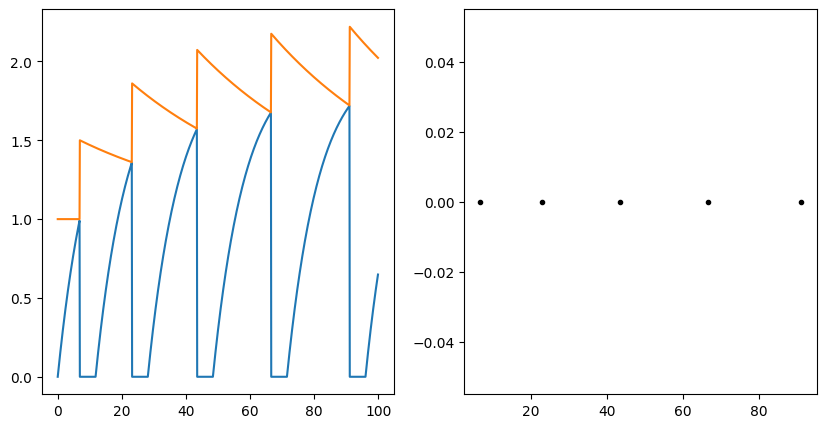

In [ ]:
start_scope()

tau=10*ms
tau_t=50*ms
f=100*Hz
eqs='''
dv/dt = (2-v)/tau : 1 (unless refractory)
dvt/dt = (1-vt)/tau_t : 1
'''
G=NeuronGroup(1,eqs,threshold='v>vt',reset='v=0; vt+=0.5',refractory=5*ms,method='euler')
G.vt=1
M=StateMonitor(G,('v','vt'), record=True)
spM = SpikeMonitor(G)
#refractory switch off the dynamics of neurons during refractory


run(100*ms)
figure(figsize=(10,5))
subplot(121)
plot(M.t/ms, M.v[0])
plot(M.t/ms, M.vt[0])
subplot(122)
plt.plot(spM.t/ms, spM.i, '.k')

INFO:root:building '_cython_magic_f98f67e88000c89328dfc06516e51d51' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_f98f67e88000c89328dfc06516e51d51.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_f98f67e88000c89328dfc06516e51d51.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_f98f67e88000c89328dfc06516e51d51.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

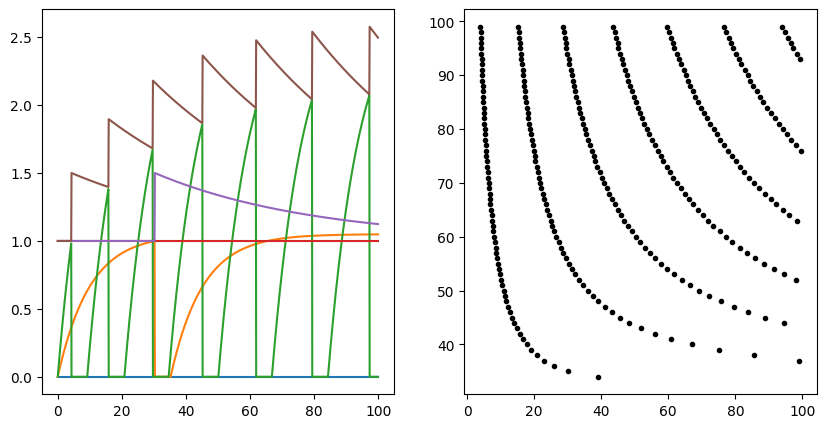

In [27]:
start_scope()

tau=10*ms
tau_t=50*ms
f=100*Hz
eqs='''
dv/dt = (I-v)/tau : 1 (unless refractory)
dvt/dt = (1-vt)/tau_t : 1
I : 1
'''
G=NeuronGroup(100,eqs,threshold='v>vt',reset='v=0; vt+=0.5',refractory=5*ms,method='euler')
G.vt = 1
#G.v = 'rand()'
G.I= '3*i/(1.0*N)'

M=StateMonitor(G,('v','vt'), record=[0,35,95])#[0,1]
spM = SpikeMonitor(G)
#refractory switch off the dynamics of neurons during refractory


run(100*ms)
figure(figsize=(10,5))
subplot(121)
plot(M.t/ms, M.v[:].T)
plot(M.t/ms, M.vt[:].T)
subplot(122)
plt.plot(spM.t/ms, spM.i, '.k')

INFO:root:building '_cython_magic_517ff92a40d6c9172b4296c802bd9c40' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_517ff92a40d6c9172b4296c802bd9c40.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_517ff92a40d6c9172b4296c802bd9c40.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_517ff92a40d6c9172b4296c802bd9c40.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

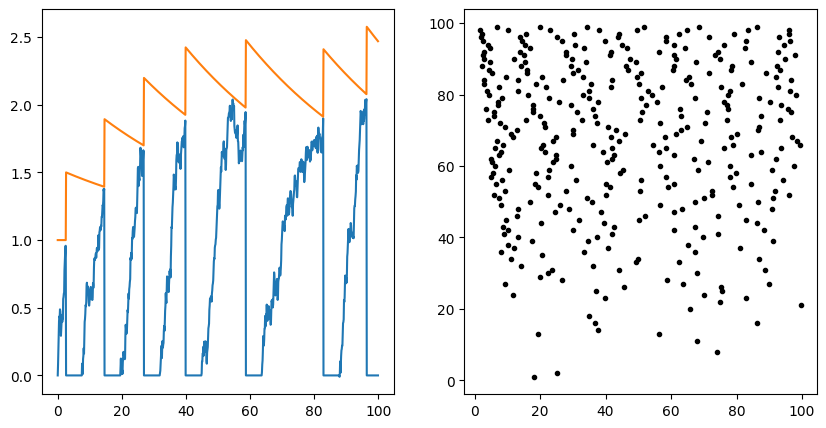

In [32]:
start_scope()

tau=10*ms
tau_t=50*ms
f=100*Hz
#calcium white noise 0 to ... 1.5 lot of noise
eqs='''
dv/dt = (I-v)/tau + 0.5*xi*tau**-0.5 : 1 (unless refractory)
dvt/dt = (1-vt)/tau_t : 1
I : 1
'''
G=NeuronGroup(100,eqs,threshold='v>vt',reset='v=0; vt+=0.5',refractory=5*ms,method='euler')
G.vt = 1
#G.v = 'rand()'
G.I= '3*i/(1.0*N)'

M=StateMonitor(G,('v','vt'), record=95)#[0,1]
spM = SpikeMonitor(G)
#refractory switch off the dynamics of neurons during refractory

net = Network(G,M,spM)

net.run(100*ms)

figure(figsize=(10,5))
subplot(121)
plot(M.t/ms, M.v[:].T)
plot(M.t/ms, M.vt[:].T)
subplot(122)
plt.plot(spM.t/ms, spM.i, '.k')

INFO:root:building '_cython_magic_04e1c6edc7f81ca37eedaf52e7bd4ac1' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_04e1c6edc7f81ca37eedaf52e7bd4ac1.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_04e1c6edc7f81ca37eedaf52e7bd4ac1.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_04e1c6edc7f81ca37eedaf52e7bd4ac1.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

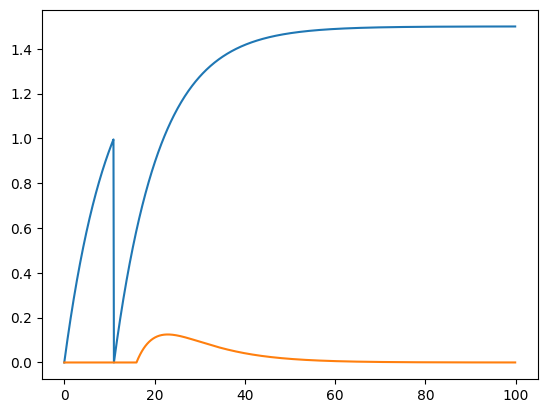

In [41]:
start_scope()

eqs = '''
dv/dt=(I+x-v)/(10*ms) : 1
dx/dt = -x/(5*ms) : 1
I : 1
'''

G=NeuronGroup(2,eqs, threshold='v>1', reset='v=0', method='exact',refractory = 200*ms)
G.I=[1.5,0]

S= Synapses(G,G,'w : 1' , on_pre='x+=0.5') #'v+=0.5; v+=0.2'
S.connect(i=0,j=1)
S.w=0.5
S.delay = 5*ms


M = StateMonitor(G, 'v', record=True)

run(100*ms)

plot(M.t/ms, M.v[:].T)


In [46]:
from brian2tools import *


INFO:root:building '_cython_magic_d4964c1dbec7b719fe89f8362d673b07' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_d4964c1dbec7b719fe89f8362d673b07.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_d4964c1dbec7b719fe89f8362d673b07.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_d4964c1dbec7b719fe89f8362d673b07.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

<Axes: xlabel='source neuron index', ylabel='target neuron index'>

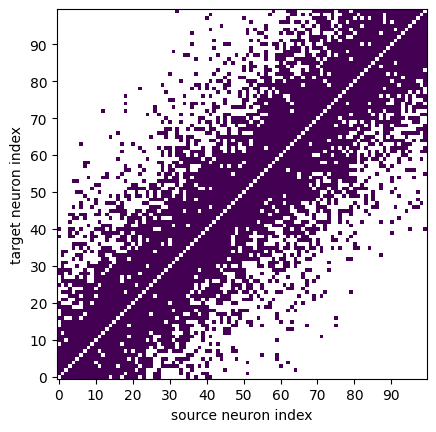

In [52]:
start_scope()



G=NeuronGroup(100,'')

S= Synapses(G,G) 
#S.connect(condition='i!=j and abs(i-j)<30')
#S.connect(p=0.5)
#S.connect(condition='i!=j and abs(i-j)<30',p=0.5)
S.connect(condition='i!=j',p='exp(-(i-j)**2/30**2)')

brian_plot(S)



INFO:root:building '_cython_magic_1ca72de1f211d1d4737ac52409b18e6a' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_1ca72de1f211d1d4737ac52409b18e6a.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_1ca72de1f211d1d4737ac52409b18e6a.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_1ca72de1f211d1d4737ac52409b18e6a.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

<Axes: xlabel='source neuron index', ylabel='target neuron index'>

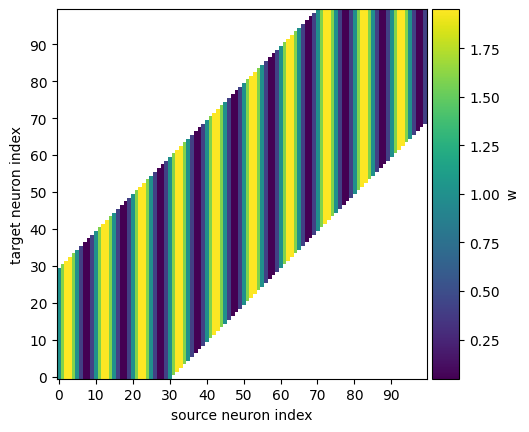

In [61]:
start_scope()

eqs = '''
x : metre
'''

G=NeuronGroup(100,eqs)
G.x = '20*um*i'
S= Synapses(G,G, 'w : 1') 

#S.connect(condition='i!=j',p='exp(-(x_pre-x_post)**2/(1000.0*um)**2)')
S.connect(j='k for k in range(i-30,i+30)', skip_if_invalid=True)

f=1/(200.0*um)
S.w = '1+sin(2*pi*f*x_pre)'

brian_plot(S.w)

In [63]:
del i,j,w

NameError: name 'i' is not defined

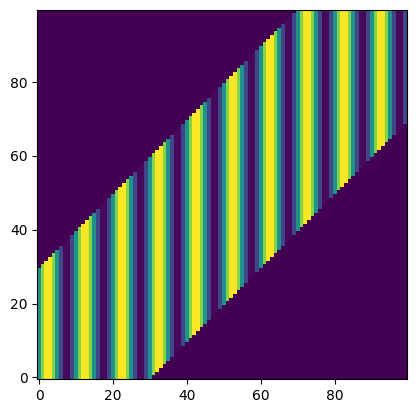

In [65]:
w = zeros((100,100))
w[S.i,S.j]=S.w
imshow(w.T, origin='lower')

In [68]:
i, j = w.nonzero()
w[i,j]
S.connect(i=i,j=j)
S.w = w[i,j]

ValueError: could not broadcast input array from shape (5100,) into shape (10200,)

INFO:root:building '_cython_magic_2f4e6cda53b9d64e035e0a62a71d1407' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_2f4e6cda53b9d64e035e0a62a71d1407.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_2f4e6cda53b9d64e035e0a62a71d1407.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_2f4e6cda53b9d64e035e0a62a71d1407.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

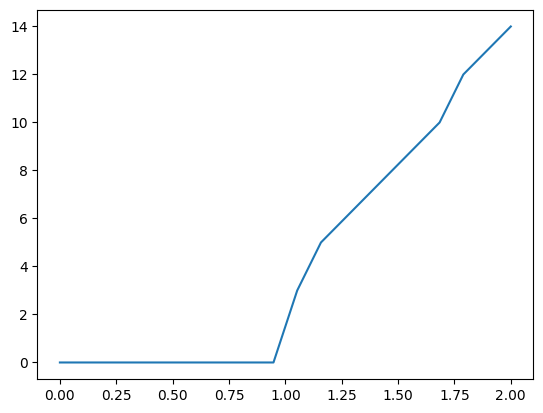

In [ ]:
start_scope()
I_values = linspace(0,2,20)
counts=[]

tau = 10*ms
eqs = '''
dv/dt = (I-v)/tau : 1
'''
G = NeuronGroup(1, eqs, threshold='v>1', reset='v=0', method='exact')
M = SpikeMonitor(G)
run(100*ms) #if want to run a small initialization first
store()

for I in I_values:
    restore()
    run(100*ms)
    counts.append(M.num_spikes)

plot(I_values,counts)

WARNING    'I' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 2.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


INFO:root:building '_cython_magic_e1400d4ad6f87dc0dede88762634f7b4' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_e1400d4ad6f87dc0dede88762634f7b4.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_e1400d4ad6f87dc0dede88762634f7b4.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_e1400d4ad6f87dc0dede88762634f7b4.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

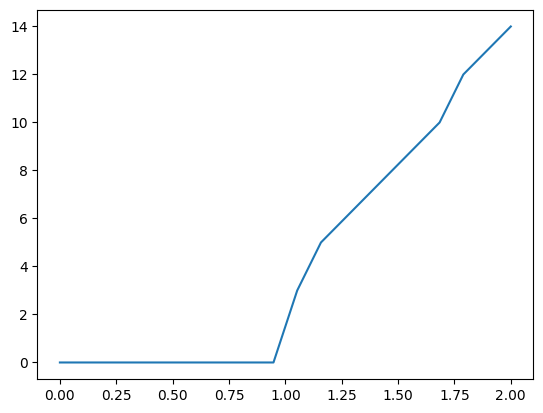

In [74]:
#right way to do it
start_scope()
I_values = linspace(0,2,20)
counts=[]

tau = 10*ms
eqs = '''
dv/dt = (I-v)/tau : 1
I : 1
'''
G = NeuronGroup(len(I_values), eqs, threshold='v>1', reset='v=0', method='exact')
G.I=I_values
M = SpikeMonitor(G)
run(100*ms)
    
plot(I_values,M.count)

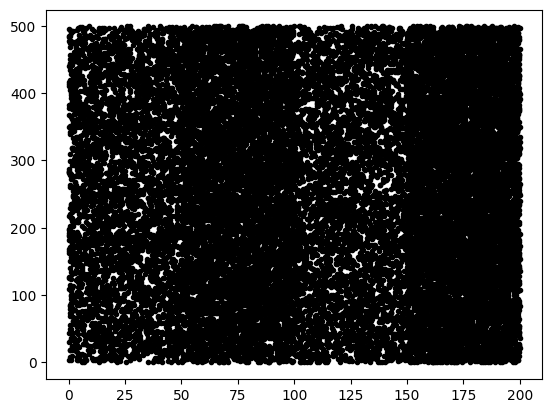

In [86]:
start_scope()

#G = PoissonGroup(100, rates = 100*Hz)
eqs='''
rates : Hz (shared)
'''
G= NeuronGroup(500, eqs, threshold='rand()<rates*dt')
M = SpikeMonitor(G)

for _ in range(4):
    G.rates='rand()*500*Hz'
    run(50*ms)

#brian_plot(M)
plot(M.t/ms, M.i, '.k')

INFO:root:building '_cython_magic_8539958bdd04d48481e1f7a8c3aa8f87' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_8539958bdd04d48481e1f7a8c3aa8f87.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_8539958bdd04d48481e1f7a8c3aa8f87.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_8539958bdd04d48481e1f7a8c3aa8f87.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

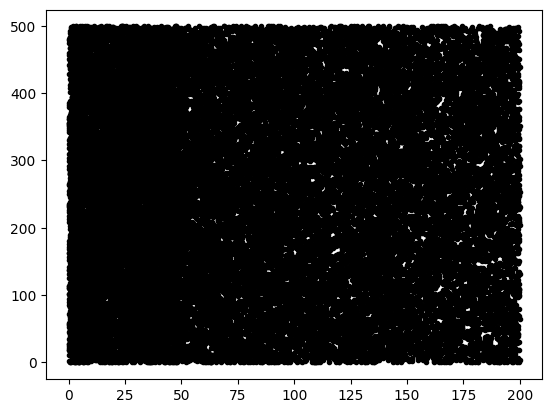

In [87]:
#right way
start_scope()

eqs='''
rates : Hz (shared)
'''
G= NeuronGroup(500, eqs, threshold='rand()<rates*dt')
M = SpikeMonitor(G)

G.run_regularly('rates = rand()*500*Hz', dt=50*ms)
run(200*ms)
#brian_plot(M)
plot(M.t/ms, M.i, '.k')

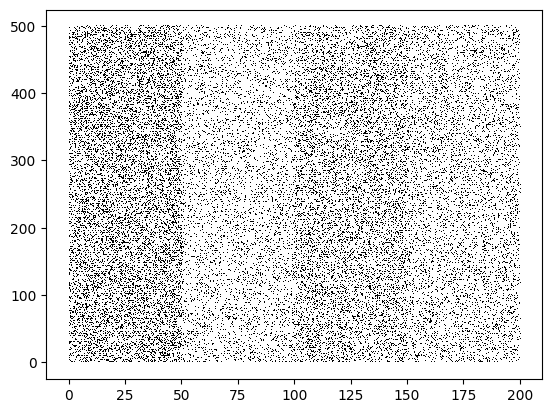

In [91]:
#other way : decorative function
start_scope()

eqs='''
rates : Hz (shared)
'''
G= NeuronGroup(500, eqs, threshold='rand()<rates*dt')
M = SpikeMonitor(G)

@network_operation(dt=50*ms)
def change_rates():
    G.rates = rand()*500*Hz

run(200*ms)
#brian_plot(M)
plot(M.t/ms, M.i, ',k')